<h1 style ="color: red; background-color: yellow; align: center; text-align: center; padding: 15px;"> Customer Segmentation on E-commerce data </h1>

In [4]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [5]:
data = pd.read_csv('data.csv',delimiter=',', encoding = "ISO-8859-1")

In [6]:
data.head(2)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [7]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB


In [8]:
data.shape

(541909, 8)

In [9]:
data.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [10]:
data.describe().T

,count,mean,std,min,25%,50%,75%,max
Quantity,541909.0,9.552250,218.081158,-80995.00,1.00,3.00,10.00,80995.0
UnitPrice,541909.0,4.611114,96.759853,-11062.06,1.25,2.08,4.13,38970.0
CustomerID,406829.0,15287.690570,1713.600303,12346.00,13953.00,15152.00,16791.00,18287.0


In [11]:
data.describe(exclude = ["int64","float64"]).T

,count,unique,top,freq
InvoiceNo,541909,25900,573585,1114
StockCode,541909,4070,85123A,2313
Description,540455,4223,WHITE HANGING HEART T-LIGHT HOLDER,2369
InvoiceDate,541909,23260,10/31/2011 14:41,1114
Country,541909,38,United Kingdom,495478


In [12]:
# dropping null values
data.dropna(inplace = True)

In [13]:
data.isnull().sum()

InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
dtype: int64

In [14]:
# checking for negative values in Quantity and Invoice no starting with C, 
# does they indicate negative values
data[data["Quantity"]<0 & data['InvoiceNo'].str.startswith("C")]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,12/1/2010 9:41,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,12/1/2010 9:49,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,12/1/2010 10:24,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,12/1/2010 10:24,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,12/1/2010 10:24,0.29,17548.0,United Kingdom
...,...,...,...,...,...,...,...,...
540449,C581490,23144,ZINC T-LIGHT HOLDER STARS SMALL,-11,12/9/2011 9:57,0.83,14397.0,United Kingdom
541541,C581499,M,Manual,-1,12/9/2011 10:28,224.69,15498.0,United Kingdom
541715,C581568,21258,VICTORIAN SEWING BOX LARGE,-5,12/9/2011 11:57,10.95,15311.0,United Kingdom
541716,C581569,84978,HANGING HEART JAR T-LIGHT HOLDER,-1,12/9/2011 11:58,1.25,17315.0,United Kingdom


InvoiceNo starting with C are cancelled orders, so we can see that all -ve quantity orders are cancelled one.

In [15]:
# dropping cancelled orders, as not align with our purpose of customer segmentation
data.drop(data[data["Quantity"]<0].index, inplace = True)

In [16]:
data.shape

(397924, 8)

# Data Preparation

In [17]:
# adding Revenue column
data['Revenue']=data['Quantity']*data['UnitPrice']

In [18]:
data.head(2)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom,20.34


#### Customer segemtation

In [19]:
# frequency -> total purchases of a customer

freq_data = data.groupby("CustomerID")['InvoiceNo'].count().reset_index()
freq_data

,CustomerID,InvoiceNo
0,12346.0,1
1,12347.0,182
2,12348.0,31
3,12349.0,73
4,12350.0,17
...,...,...
4334,18280.0,10
4335,18281.0,7
4336,18282.0,12
4337,18283.0,756


In [20]:
# monetary -> revenue contribution of a customer

revenue_contri = data.groupby("CustomerID")['Revenue'].sum().reset_index()
revenue_contri

,CustomerID,Revenue
0,12346.0,77183.60
1,12347.0,4310.00
2,12348.0,1797.24
3,12349.0,1757.55
4,12350.0,334.40
...,...,...
4334,18280.0,180.60
4335,18281.0,80.82
4336,18282.0,178.05
4337,18283.0,2094.88


In [21]:
# recency -> days last transaction happens for each customer

data['InvoiceDate']=pd.to_datetime(data['InvoiceDate'])
data['LastTransaction'] = (max(data['InvoiceDate']) - data['InvoiceDate']).dt.days


In [22]:
data.head(2)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue,LastTransaction
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30,373
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,373


In [23]:
recency_df = data.groupby(['CustomerID','Country'])['LastTransaction'].max().reset_index()
recency_df

,CustomerID,Country,LastTransaction
0,12346.0,United Kingdom,325
1,12347.0,Iceland,366
2,12348.0,Finland,357
3,12349.0,Italy,18
4,12350.0,Norway,309
...,...,...,...
4342,18280.0,United Kingdom,277
4343,18281.0,United Kingdom,180
4344,18282.0,United Kingdom,125
4345,18283.0,United Kingdom,336


In [24]:
# MERGING recency, frequency, and revenue contribution data

rfm_data = pd.merge(recency_df, revenue_contri, how='inner', on='CustomerID')
rfm_data = pd.merge(freq_data, rfm_data, how='inner', on='CustomerID')
rfm_data.rename(columns = {'InvoiceNo': 'Frequency'},inplace = True)
rfm_data # final dataset

,CustomerID,Frequency,Country,LastTransaction,Revenue
0,12346.0,1,United Kingdom,325,77183.60
1,12347.0,182,Iceland,366,4310.00
2,12348.0,31,Finland,357,1797.24
3,12349.0,73,Italy,18,1757.55
4,12350.0,17,Norway,309,334.40
...,...,...,...,...,...
4342,18280.0,10,United Kingdom,277,180.60
4343,18281.0,7,United Kingdom,180,80.82
4344,18282.0,12,United Kingdom,125,178.05
4345,18283.0,756,United Kingdom,336,2094.88


##### Outliers treatment

<AxesSubplot:xlabel='Revenue'>

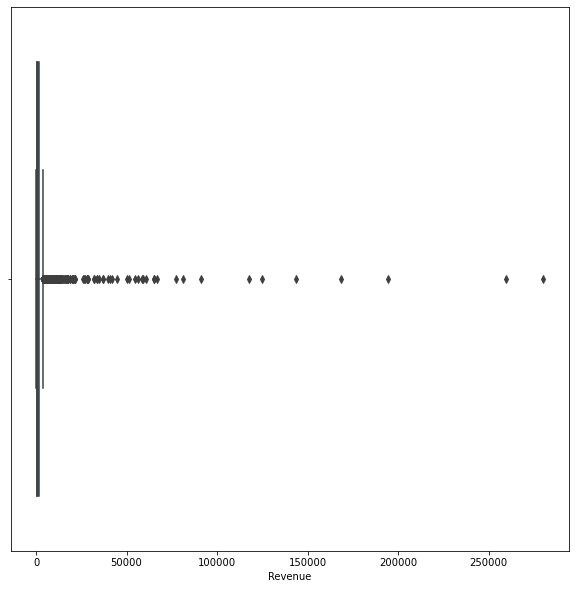

In [25]:
fig,ax = plt.subplots(figsize=(10,10))
sns.boxplot(data=rfm_data,x="Revenue",ax=ax)

In [26]:
rfm_data = rfm_data[rfm_data['Revenue']<=6000].copy()
# dropping values with revenue greater than 6000, bcz after that we can see inconsistent jump.

<AxesSubplot:xlabel='Revenue'>

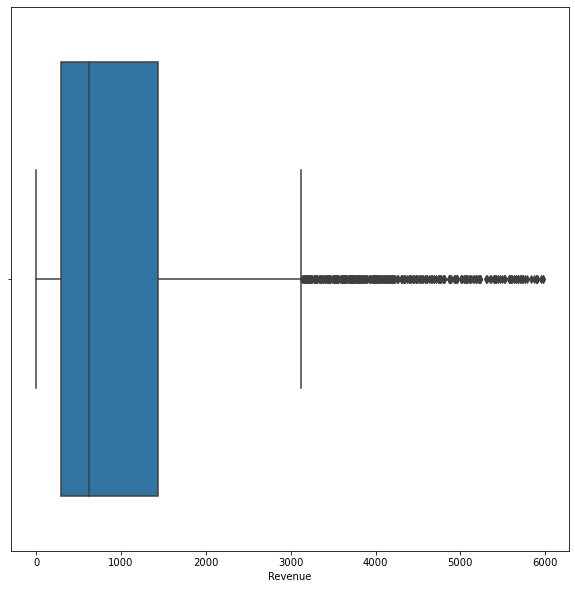

In [27]:
fig,ax = plt.subplots(figsize=(10,10))
sns.boxplot(data=rfm_data,x="Revenue",ax=ax)

In [28]:
rfm_data.head(2)

,CustomerID,Frequency,Country,LastTransaction,Revenue
1,12347.0,182,Iceland,366,4310.00
2,12348.0,31,Finland,357,1797.24


<AxesSubplot:xlabel='Frequency'>

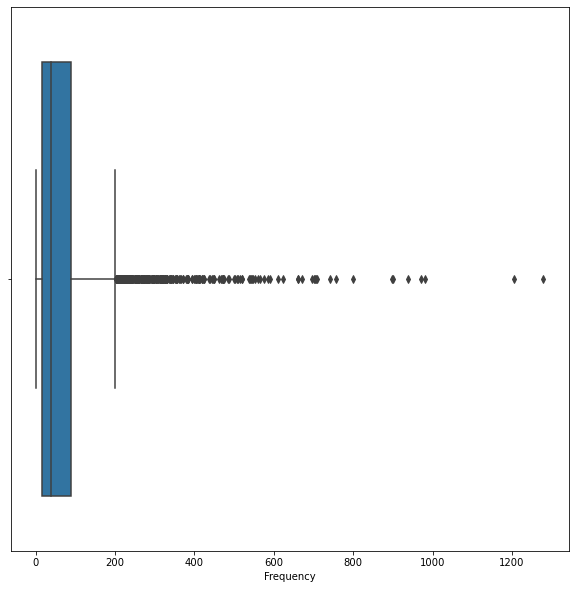

In [29]:
fig,ax = plt.subplots(figsize=(10,10))
sns.boxplot(data=rfm_data,x="Frequency",ax=ax)

Value of frequency as 1200 means a customer is ordering 3 times a day for 373 days. Its rare but possible. Yet we will keep only values < 800, because we can see big jump there.

In [30]:
rfm_data = rfm_data[rfm_data['Frequency']<=800].copy()

<AxesSubplot:xlabel='Frequency'>

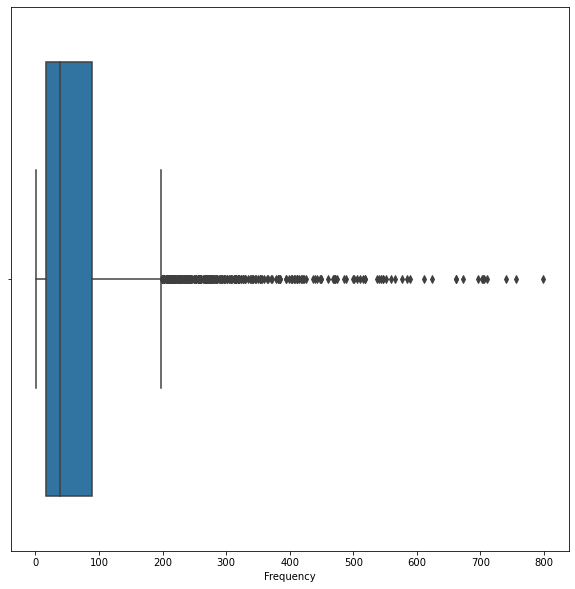

In [31]:
fig,ax = plt.subplots(figsize=(10,10))
sns.boxplot(data=rfm_data,x="Frequency",ax=ax)

In [32]:
rfm_data.reset_index(drop=True, inplace=True)
rfm_data

,CustomerID,Frequency,Country,LastTransaction,Revenue
0,12347.0,182,Iceland,366,4310.00
1,12348.0,31,Finland,357,1797.24
2,12349.0,73,Italy,18,1757.55
3,12350.0,17,Norway,309,334.40
4,12352.0,85,Norway,296,2506.04
...,...,...,...,...,...
4125,18280.0,10,United Kingdom,277,180.60
4126,18281.0,7,United Kingdom,180,80.82
4127,18282.0,12,United Kingdom,125,178.05
4128,18283.0,756,United Kingdom,336,2094.88


In [33]:
rfm_data.shape

(4130, 5)

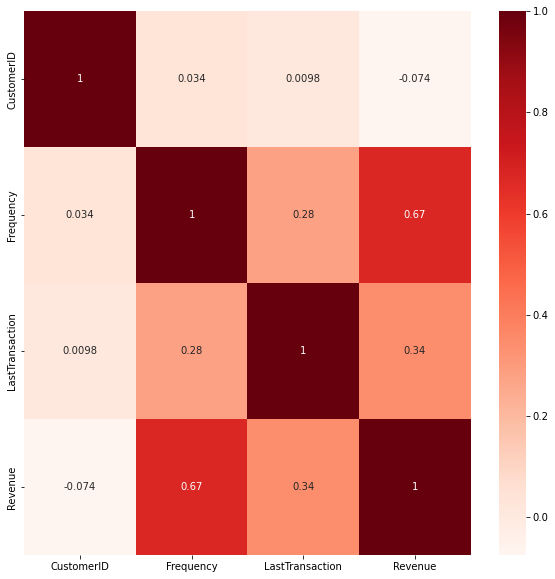

In [34]:
# checking for correlation

fig , ax = plt.subplots(figsize=(10,10))
sns.heatmap(rfm_data.corr(),cmap="Reds",annot=True)
plt.show()

#### Normalization

In [35]:
from sklearn.preprocessing import MinMaxScaler

In [36]:
temp_df=rfm_data[['Revenue','LastTransaction','Frequency']]
scaler = MinMaxScaler()
scaled_df = scaler.fit_transform(temp_df)
scaled_df = pd.DataFrame(scaled_df,columns = ['Revenue','LastTransaction','Frequency'])
scaled_df['Country'] = rfm_data['Country']
scaled_df.head(2)

,Revenue,LastTransaction,Frequency,Country
0,0.721009,0.981233,0.226817,Iceland
1,0.300656,0.957105,0.037594,Finland


# Modeling

### K-means Clustering

Plotting the graph for k against WCSS to identify elbow for finding optimal value of K

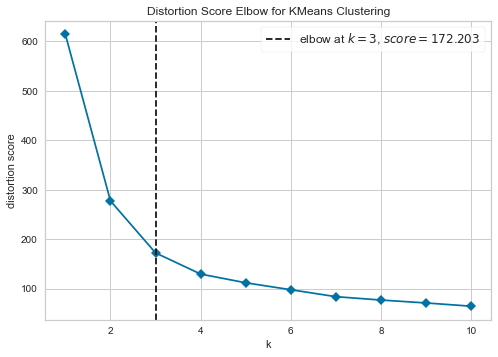

<AxesSubplot:title={'center':'Distortion Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='distortion score'>

In [37]:
df_k = scaled_df.drop(columns = ['Country'], axis =1)

# importing ELbowVisualizer
from yellowbrick.cluster import KElbowVisualizer
from sklearn.cluster import KMeans

model = KMeans()

visualizer = KElbowVisualizer(model, k = (1,11), timings = False)
visualizer.fit(df_k)
visualizer.show()

In [38]:
# training and predicting
kmeans_model = KMeans(n_clusters = 3,random_state=42)
y_predict = kmeans_model.fit_predict(df_k)

df_k['Clusters'] = y_predict

df_k

,Revenue,LastTransaction,Frequency,Clusters
0,0.721009,0.981233,0.226817,1
1,0.300656,0.957105,0.037594,0
2,0.294016,0.048257,0.090226,2
3,0.055941,0.828418,0.020050,0
4,0.419229,0.793566,0.105263,1
...,...,...,...,...
4125,0.030212,0.742627,0.011278,0
4126,0.013520,0.482574,0.007519,2
4127,0.029786,0.335121,0.013784,2
4128,0.350447,0.900804,0.946115,1


In [39]:
df_k['Clusters'].unique()

array([1, 0, 2])

In [40]:
kmeans_model.cluster_centers_

array([[0.12561401, 0.78224955, 0.06152243],
       [0.5629287 , 0.84539022, 0.25889222],
       [0.10305852, 0.22694515, 0.05219924]])

In [41]:
kmeans_model.labels_

array([1, 0, 2, ..., 2, 1, 0])

## Evaluation using silhouette_score

In [42]:
from sklearn.metrics import silhouette_score
score = silhouette_score(df_k,kmeans_model.labels_,metric='euclidean')
score

0.7912417057663124

### Saving model

In [43]:
import pickle
pickle.dump(kmeans_model,open("customer_segementation_model.pkl", "wb"))